In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="darkgrid")

In [38]:
BASE = "https://raw.githubusercontent.com/iabufarha/ArSarcasm-v2/main/ArSarcasm-v2/"
df = pd.read_csv(BASE + "training_data.csv")
df.head(5)

,tweet,sarcasm,sentiment,dialect
0,"""د. #محمود_العلايلي:أرى أن الفريق #أحمد_شفيق ر...",False,NEU,msa
1,"""مع فيدرر يا آجا والكبار 😍 https://t.co/hrBeHb...",False,NEU,msa
2,“الداعون لمبدأ الاختلاط بين الجنسين؛ كالداعين ...,True,NEG,msa
3,"""@ihe_94 @ya78m @amooo5 @badiajnikhar @Oukasaf...",True,NEG,gulf
4,"""قل شرق حلب ولا تقل حلب الشرقية ....وقل غرب حل...",False,NEU,msa


In [39]:
df.describe(include='all')

,tweet,sarcasm,sentiment,dialect
count,12548,12548,12548,12548
unique,12487,2,3,5
top,"""RT @M__albugaily: قردوغان حليف اسرائيل يدعم ت...",False,NEU,msa
freq,3,10380,5747,8562


In [40]:
df.dtypes

tweet         str
sarcasm      bool
sentiment     str
dialect       str
dtype: object

In [41]:
df.isnull().sum()

tweet        0
sarcasm      0
sentiment    0
dialect      0
dtype: int64

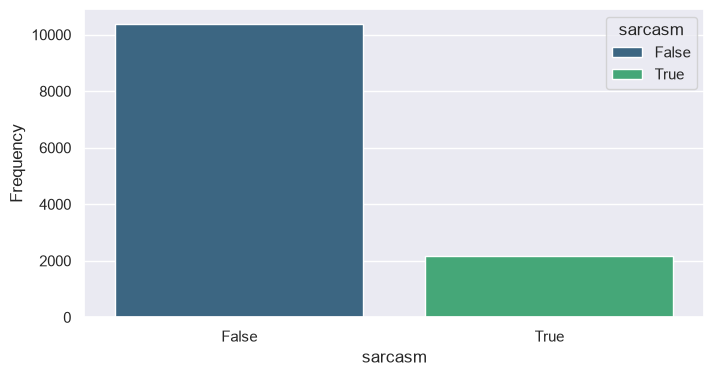

In [42]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='sarcasm', palette='viridis', hue='sarcasm', dodge=False)

plt.xlabel('sarcasm')
plt.ylabel('Frequency')
plt.show()

In [43]:
for tweet in df[df['sarcasm'] == 1]['tweet'].sample(n=2).values:
    print("Sarcastic Tweet: ", tweet)
    print()

print("#" * 50)

for tweet in df[df['sarcasm'] == 0]['tweet'].sample(n=2).values:
    print("Non-Sarcastic Tweet: ", tweet)
    print()


Sarcastic Tweet:  والله زمن الي وافد ايراني كان يشتغل في بقالة بالسالمية صار ممثل وحكها مع كبارية وبعدها قام يغلط على أهل الكويت   #ويقولون الفن مايوكل خبز

Sarcastic Tweet:  خليك كوبري #عسكر #اخوان لايق عليك # #قانون_التظاهر #قصر_الاتحادية #اسقاط_قانون_التظاهر #6ابريل

##################################################
Non-Sarcastic Tweet:  "الرئيس ميشال عون: ما يقوم به جيشنا في الداخل يستطيع أيضاً أن يقوم به على الحدود، فعندما تهدّد الأخطار الوطن يبقى... https://t.co/V3m0iUGYWN"

Non-Sarcastic Tweet:  "يحذر موقع #طقس_العرب هذه الليلة وفجر الأحد من تشكل الضباب الكثيف أحياناً في المناطق التالية :1- طريق المطار... https://t.co/Gol0pcMElr"



so we have class imbalance issue.

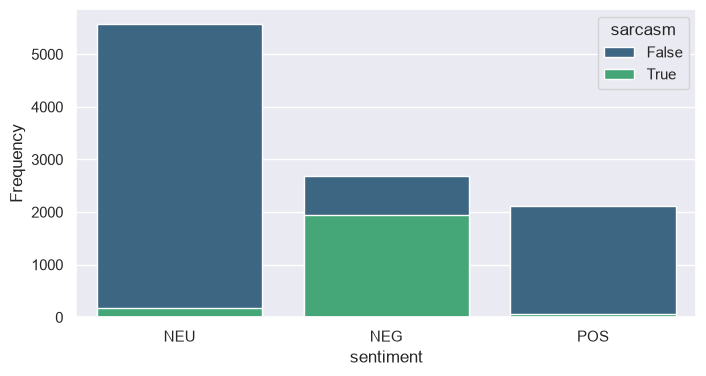

In [44]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='sentiment', palette='viridis', hue='sarcasm', dodge=False)

plt.xlabel('sentiment')
plt.ylabel('Frequency')
plt.show()

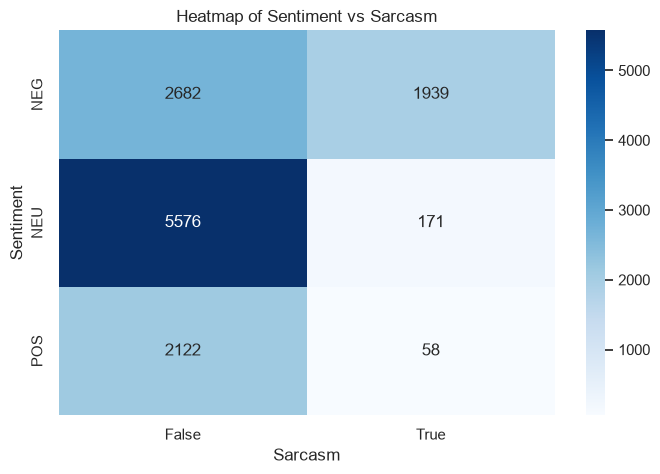

In [45]:
plt.figure(figsize=(8, 5))
sns.heatmap(
    pd.crosstab(df['sentiment'], df['sarcasm']),
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=True,
)

plt.title('Heatmap of Sentiment vs Sarcasm')
plt.xlabel('Sarcasm')
plt.ylabel('Sentiment')
plt.show()

In [46]:

sentiments = {
    "POS": "Positive",
    "NEG": "Negative",
    "NEU": "Neutral"
}

sarcasm_types = {
    1: "Sarcastic",
    0: "Non-Sarcastic"
}

for sentiment, sentiment_label in sentiments.items():
    for sarcasm, sarcasm_label in sarcasm_types.items():

        print(f"\n{'#' * 50}")
        print(f"{sarcasm_label} and {sentiment_label} tweets:")
        print("-" * 50)

        tweets = df[
            (df["sentiment"] == sentiment) &
            (df["sarcasm"] == sarcasm)
        ]["tweet"].sample(n=2)

        if tweets.empty:
            print("No tweets found for this category.")
            continue

        for i, tweet in enumerate(tweets, start=1):
            print(f"{i}. {tweet}\n")



##################################################
Sarcastic and Positive tweets:
--------------------------------------------------
1. تسلم الايادي يا جيش بلادي و يا شعب بلادي #تحرير_سيناء من الصهاينه + الاخوان

2. "كلها بقت احمد الشيخ اهو 😂"


##################################################
Non-Sarcastic and Positive tweets:
--------------------------------------------------
1. RT @kimo7879: #السعوديه_الاماراتميسي:ماذا فعلت بهم ياصديقي فهد ؟!فهدلميسي: من متى المعرفه 😂😂😂😂😂😂#عودة_بطل #فهد_المولد#منتخبنا_اولا #مع…

2. "#فلسطين  ايتها البعيدة عنا .....القريبة منا ياقطعة شمس تغطينا....ياروحا تسكن فينا#الحريةلفلسطين… https://t.co/9K8eAZigUD"


##################################################
Sarcastic and Negative tweets:
--------------------------------------------------
1. "صدف اني شفت فيديو كليب اجنبي لمغنية كنت اشوفها راقية إلى حد ما.. وشفت فيديو كليب ميريام فارس، واثنينهم كانوا بالنسبة لي مقدمة فلم سكس او سكس"

2. "من قايل لجراح الهبيده انك حلو ؟ والله يا معطي نفسه وضعيه جستن بي

the most of the tweets are sarcastic and negative 

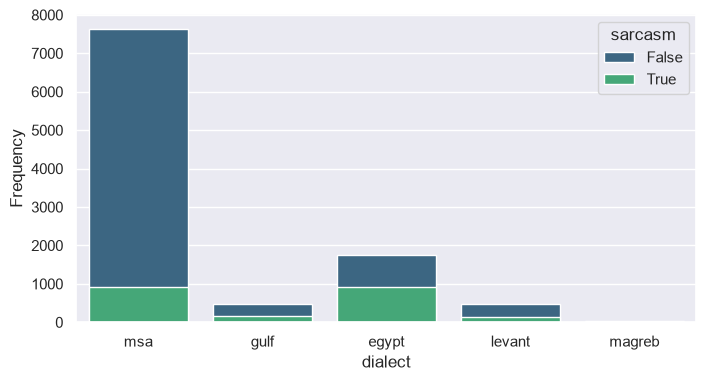

In [47]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='dialect', palette='viridis', hue='sarcasm', dodge=False)

plt.xlabel('dialect')
plt.ylabel('Frequency')
plt.show()

In [48]:
dialects = df["dialect"].dropna().unique()

for dialect in dialects:
    for sarcasm, sarcasm_label in {
        1: "Sarcastic",
        0: "Non-Sarcastic"
    }.items():

        print(f"\n{'#' * 60}")
        print(f"Dialect: {dialect} | {sarcasm_label} Tweets")
        print("-" * 60)

        tweets = df[
            (df["dialect"] == dialect) &
            (df["sarcasm"] == sarcasm)
        ]["tweet"].dropna()

        tweets = tweets.sample(n=2)

        for i, tweet in enumerate(tweets, start=1):
            print(f"{i}. {tweet}\n")


############################################################
Dialect: msa | Sarcastic Tweets
------------------------------------------------------------
1. جماعه لو في حد عنده عسر هضم أو مزنوق مش عارف يفك زنقته يعمل مظاهره أو إئتلاف ويسميه إئتلاف العجز عن الفك   مبهره الصراحه

2. المصري يضرب مراته و عياله، و يجيب ف سيرة الناس ع القهوة، و يعاكس الرايحة و الجاية .. و ينتخب السلفيين! #Egypt  


############################################################
Dialect: msa | Non-Sarcastic Tweets
------------------------------------------------------------
1. "قال رسول الله صلى الله عليه وسلم:أفضل الصيام بعد رمضان:شهر الله المحرم وأفضل الصلاة بعد الفريضة:صلاة الليل -- حديث صحيح #قيام_الليل #Hadith"

2. "الناتو نفذ 30 ألف غارة بليبيا 2011 دمروا الجيش وقتلوا 30 ألف مقاتل بهدف السيطرة على خيراتها وسيطرت إيطاليا على قاعدة الجفرة ."


############################################################
Dialect: gulf | Sarcastic Tweets
------------------------------------------------------------
1. عزيزي أل

# Text statistics

In [49]:
from collections import Counter
import plotly.express as px
import emoji

LABELS = ["Non-sarcastic", "Sarcastic"]
COLORS = {"Non-sarcastic": "steelblue", "Sarcastic": "tomato"}

# Clean copy: readable labels, no missing tweets
data = df[["tweet", "sarcasm"]].dropna().copy()
data["tweet"] = data["tweet"].astype(str)
data["sarcasm"] = data["sarcasm"].astype(str).str.lower().map({
    "true": "Sarcastic", "1": "Sarcastic",
    "false": "Non-sarcastic", "0": "Non-sarcastic",
})
data = data.dropna(subset=["sarcasm"])

# Class sizes, used to keep every comparison fair
class_sizes = data["sarcasm"].value_counts().reindex(LABELS)
class_sizes

sarcasm
Non-sarcastic    10380
Sarcastic         2168
Name: count, dtype: int64

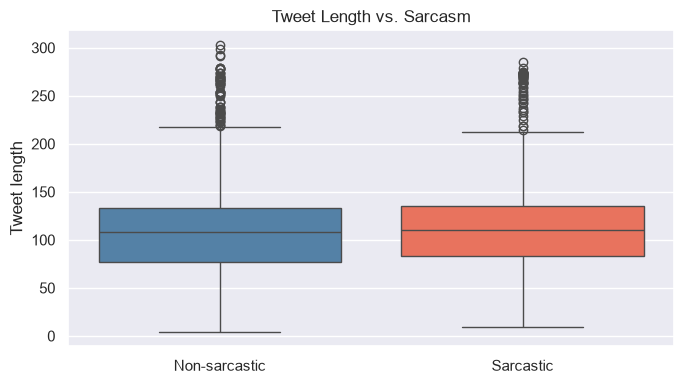

,count,mean,median
sarcasm,,,
Non-sarcastic,10380,101.87,108.0
Sarcastic,2168,107.85,110.0


In [50]:
data["tweet_length"] = data["tweet"].str.len()

plt.figure(figsize=(7, 4))
sns.boxplot(data=data, x="sarcasm", y="tweet_length", order=LABELS,
            hue="sarcasm", palette=COLORS, legend=False)
plt.xlabel("")
plt.ylabel("Tweet length")
plt.title("Tweet Length vs. Sarcasm")
plt.tight_layout()
plt.show()

data.groupby("sarcasm")["tweet_length"].agg(["count", "mean", "median"]).round(2).reindex(LABELS)

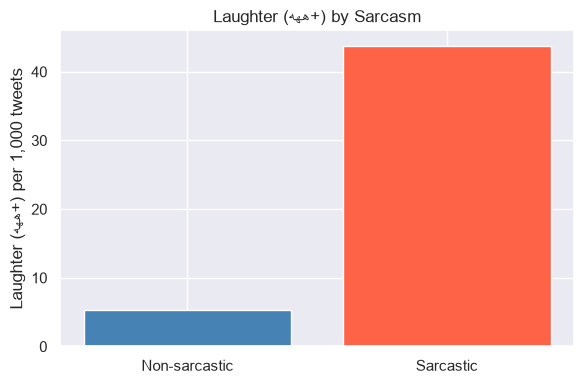

,total_occurrences,tweets_with_laughter,tweets_with_laughter_%,occurrences_per_1000_tweets
sarcasm,,,,
Non-sarcastic,55,54,0.52,5.30
Sarcastic,95,86,3.97,43.82


In [51]:
# Laughter: "ههه" or longer (3+ consecutive ه), each run counts as one occurrence
data["Laughter (ههه+)"] = data["tweet"].str.count(r"ه{3,}")

plot_rate("Laughter (ههه+)")

# Raw counts next to the fair numbers
laugh = data.groupby("sarcasm").agg(
    total_occurrences=("Laughter (ههه+)", "sum"),
    tweets_with_laughter=("Laughter (ههه+)", lambda s: (s > 0).sum()),
).reindex(LABELS)

laugh["tweets_with_laughter_%"] = (laugh["tweets_with_laughter"] / class_sizes * 100).round(2)
laugh["occurrences_per_1000_tweets"] = (laugh["total_occurrences"] / class_sizes * 1000).round(2)
laugh

In [52]:
data["emojis"] = data["tweet"].apply(lambda t: [e["emoji"] for e in emoji.emoji_list(t)])

# Emoji counts per class, converted to appearances per 1,000 tweets
emoji_counts = pd.DataFrame({
    label: Counter(e for emojis in group for e in emojis)
    for label, group in data.groupby("sarcasm")["emojis"]
}).fillna(0)
emoji_rates = emoji_counts.div(class_sizes) * 1000

top10 = emoji_rates.sum(axis=1).nlargest(10).index
plot_data = (emoji_rates.loc[top10]
             .rename_axis("Emoji").reset_index()
             .melt(id_vars="Emoji", var_name="Sarcasm", value_name="Appearances per 1,000 tweets"))

fig = px.bar(plot_data, x="Appearances per 1,000 tweets", y="Emoji",
             color="Sarcasm", barmode="group", orientation="h",
             color_discrete_map=COLORS, title="Top 10 Emojis by Sarcasm")
fig.update_yaxes(autorange="reversed")  # most frequent emoji on top
fig.update_layout(height=500)
fig.show()

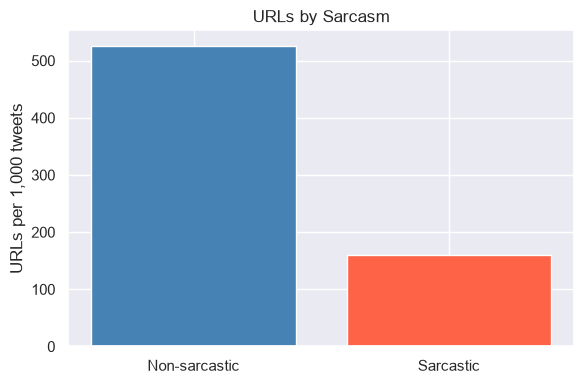

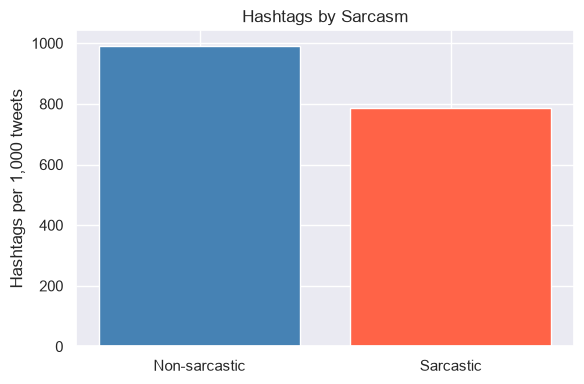

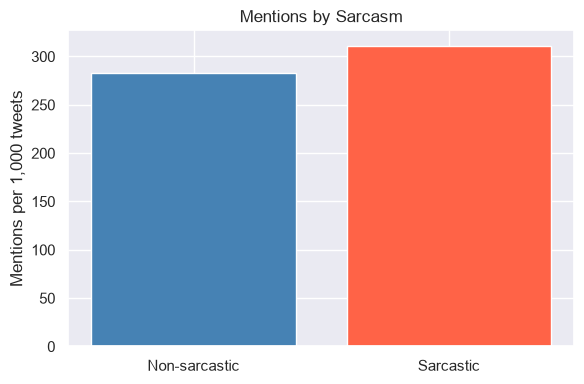

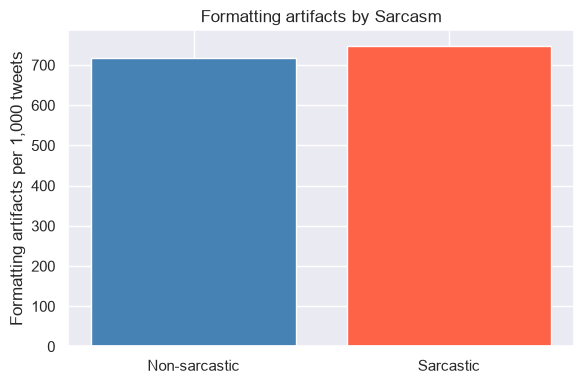

In [53]:
PATTERNS = {
    "URLs": r"https?://\S+|www\.\S+",
    "Hashtags": r"(?<!\w)#\w+",
    "Mentions": r"(?<!\w)@\w+",
    "Formatting artifacts": r"<[^>]+>|&(?:amp|lt|gt|quot|apos|nbsp);|&#\d+;|\\u[0-9a-fA-F]{4}|[*_~`]+",
}

def plot_rate(feature):
    """Bar plot of a counted feature, per 1,000 tweets in each class."""
    rates = (data.groupby("sarcasm")[feature].sum() / class_sizes * 1000).reindex(LABELS)

    plt.figure(figsize=(6, 4))
    plt.bar(rates.index, rates.values, color=[COLORS[l] for l in rates.index])
    plt.title(f"{feature} by Sarcasm")
    plt.ylabel(f"{feature} per 1,000 tweets")
    plt.tight_layout()
    plt.show()

for name, pattern in PATTERNS.items():
    data[name] = data["tweet"].str.count(pattern)
    plot_rate(name)